# Pydantic 인자와 반환 스키마

**이 노트북에서 할 일**

1. Ch 6 03절의 양식 클래스로 도구의 입력 형식을 적고, 도구 명세에 무엇이 들어가는지 봅니다.
2. 도구가 내놓은 주문 줄을 다른 양식 클래스로 코드에서 검사합니다.
3. 없는 상태 이름을 넣으면 01절 도구가 오류 없이 빈 목록을 내놓는 것을 봅니다(Before).
4. 양식 클래스를 붙인 도구가 같은 값을 몸통 실행 전에 막는 것을 봅니다(After).

**준비물** — 이 절은 모델을 부르지 않습니다.
모델 요청은 0번이라 API 키가 필요 없고, 드는 비용도 없습니다.
입력 형식 검사는 도구를 부르는 프로그램 안에서 일어나서 모델 없이 볼 수 있기 때문입니다.
모델이 도구 명세를 읽고 인자를 적어 보내는 장면은 04절부터 봅니다.

읽는 파일은 실습 폴더의 `data/orders.csv` 하나이고, 새로 쓰는 파일은 없습니다.
Ch 4 함수 `fetch_orders`는 같은 폴더의 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 3초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2입니다.
함께 설치하는 pandas는 3.0.5, pydantic은 2.12.5입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
양식 클래스로 입력 형식을 적고, 도구가 내놓은 값을 검사하는 자리입니다.
6~8절은 없는 상태를 넣어 보고, 막는 모습을 보고, 값을 바꿔 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 칸 양식 클래스 OrderQuery 안에 파란 상자 둘 상태 칸 status Literal 세 글 가운데 하나와 최대 개수 칸 limit Field 1 이상 10 이하가 나란히 있고, 이 칸에서 회색 상자 @tool args_schema=OrderQuery 도구 search_orders로 이어지며, 거기서 노란 상자 셋 입력 형식 양식 클래스의 칸과 같은가 True, 명세의 status 칸 enum 세 글 paid pending cancelled, 명세의 limit 칸 minimum 1 maximum 10으로 나뉘는 그림](attachment:02-1-양식-클래스에서-도구-명세로.png)

위에서 아래로 읽습니다. 맨 위 칸이 우리가 적은 양식 클래스이고, 파란 상자 둘이 그 칸 둘입니다.
가운데 회색 상자는 LangChain의 `@tool` 줄이 양식 클래스를 입력 형식으로 붙여 만든 도구입니다.
아래 노란 상자 셋은 노트북 4절이 출력한 입력 형식과 도구 명세의 두 칸입니다.
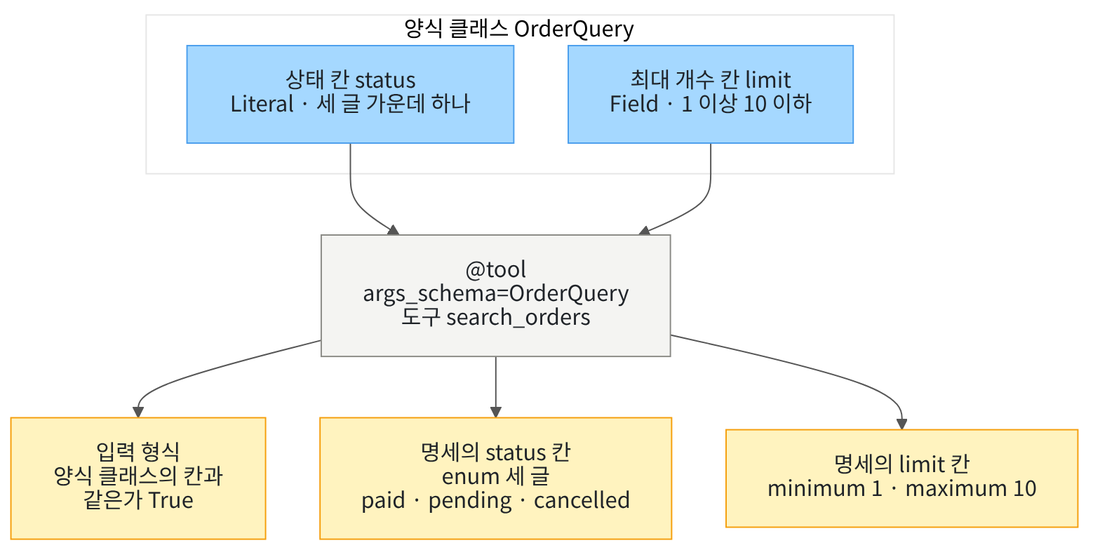

## 1. 준비

이 절은 01절 도구의 입력 형식에 고를 수 있는 값과 범위를 적습니다.
제목의 Pydantic은 Ch 6 03절에서 쓴 양식 클래스 `BaseModel`을 주는 라이브러리 이름입니다.
제목의 반환 스키마는 도구가 내놓는 값의 칸을 코드로 검사하는 틀을 뜻합니다.
이 틀은 모델에게 전해지지 않고, 그 까닭은 5절에서 출력으로 봅니다.

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "pandas==3.0.5" "pydantic==2.12.5"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("pandas:", version("pandas"))
print("pydantic:", version("pydantic"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
pandas: 3.0.5
pydantic: 2.12.5


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`pandas: 3.0.5`·`pydantic: 2.12.5`가 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 절에서 쓸 이름 여덟을 가져옵니다.
이름 `Literal`은 3절에서 칸에 적을 수 있는 값을 몇 개로 정할 때 씁니다.
이름 `BaseModel`·`Field`·`ValidationError`는 Ch 6 03절에서 쓴 양식 틀·칸 규칙·값 검사 오류입니다.
함수 `tool`과 `convert_to_openai_tool`은 01절에서 쓴 이름입니다.

In [2]:
# CSV 위치를 찾을 os, 칸 값을 정하는 Literal, 양식 클래스 이름들, 도구를 만드는 이름들, Ch 4 함수를 가져옵니다
import os
from typing import Literal

from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool
from pydantic import BaseModel, Field, ValidationError

from order_tools import fetch_orders

print("가져온 이름:", "os", "Literal", "tool", "convert_to_openai_tool")
print("가져온 이름:", "BaseModel", "Field", "ValidationError", "fetch_orders")

가져온 이름: os Literal tool convert_to_openai_tool
가져온 이름: BaseModel Field ValidationError fetch_orders


**결과 읽기** — 출력 두 줄에 가져온 이름 여덟이 보입니다.
함수 `fetch_orders`는 01절처럼 도구 파일에서 가져왔습니다.

다음 셀은 01절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
후보 세 곳을 차례로 보고, 파일이 있는 첫 자리에서 `break`로 멈춥니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.
변수 `csv_path`에 CSV 파일 위치를 담았습니다.

## 2. 01절 도구 다시 보기

01절은 Ch 4 함수를 부르는 작은 함수를 `@tool` 줄로 감싸 도구를 만들었습니다.
이 노트북은 01절 노트북과 따로 실행되므로, 다음 셀에 01절 3절 셀을 그대로 다시 적습니다.
6절 Before에서 이 도구를 씁니다.

In [4]:
# Ch 4 함수를 부르는 작은 함수를 도구로 감쌉니다(CSV 파일 위치는 노트북이 정하고, 상태만 인자로 받습니다)
@tool
def list_orders_by_status(status: str):
    """주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다."""
    # 몸통은 Ch 4 함수를 한 번 부르는 한 줄입니다
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `list_orders_by_status`는 상태 글 하나를 받아 그 상태의 주문 목록을 내놓는 도구가 되었습니다.

다음 셀은 이 도구의 입력 형식과 도구 설명을 다시 봅니다.

In [5]:
# 01절 도구의 입력 형식과 도구 설명을 다시 봅니다
print("입력 형식:", list_orders_by_status.args)
print("도구 설명:", list_orders_by_status.description)

입력 형식: {'status': {'title': 'Status', 'type': 'string'}}
도구 설명: 주문 상태(paid, pending, cancelled)를 받아 그 상태의 주문 목록을 찾습니다.


**결과 읽기** — 출력 줄 `입력 형식: {'status': {'title': 'Status', 'type': 'string'}}`는 01절 4절 출력과 같습니다.
입력 형식이 알려 주는 것은 인자 `status`가 글이라는 것뿐입니다.
고를 수 있는 상태 셋 `paid, pending, cancelled`는 출력 줄 `도구 설명:` 뒤 글에만 있습니다.

설명 글에 적은 상태 셋을 도구가 검사하는지는 6절에서 봅니다.

## 3. 양식 클래스로 고를 수 있는 값 적기

Ch 6 03절은 칸과 규칙을 적은 양식 클래스 `StudyCard`를 만들었습니다.
클래스 이름 뒤 괄호에 `BaseModel`을 적으면, 칸마다 적은 자료형과 규칙으로 값을 검사하는 양식이 됩니다.
양식 클래스는 Ch 2 10절에서 자세히 다룹니다.
Ch 2에서 건너뛸 수 있는 절이라, 배우지 않았다면 칸과 규칙을 적은 양식으로 읽으면 됩니다.

이번 양식 클래스 `OrderQuery`에는 칸이 둘입니다.
상태 칸의 `Literal["paid", "pending", "cancelled"]`은 괄호 안 세 글 가운데 하나만 적을 수 있다는 표시입니다.
최대 개수 칸의 `Field(ge=1, le=10)`은 Ch 6 03절처럼 1 이상 10 이하라는 규칙입니다.
식당으로 치면 상태 칸은 동그라미 셋 가운데 하나를 칠하는 전표 칸입니다.

In [6]:
# 주문 상태와 최대 개수 두 칸을 가진 주문 찾기 양식을 정합니다
class OrderQuery(BaseModel):
    # 상태 칸에는 괄호 안 세 글 가운데 하나만 적을 수 있습니다
    status: Literal["paid", "pending", "cancelled"] = Field(description="찾을 주문 상태")
    # 최대 개수 칸은 1 이상 10 이하의 정수입니다
    limit: int = Field(ge=1, le=10, description="받을 주문의 최대 개수")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
두 칸 모두 기본값을 적지 않아, 두 칸 모두 꼭 채워야 하는 칸입니다.

다음 셀은 규칙 안의 값으로 양식 객체 하나를 직접 만듭니다.
Ch 6 03절에서 카드 하나를 키워드 인자로 만든 것과 같은 방법입니다.

In [7]:
# 규칙 안의 값으로 양식 객체 하나를 직접 만들고 칸 값을 읽습니다(도구 없음)
sample_query = OrderQuery(status="paid", limit=2)
print("양식 객체:", sample_query)
print("상태 칸:", sample_query.status)
print("최대 개수 칸:", sample_query.limit)

양식 객체: status='paid' limit=2
상태 칸: paid
최대 개수 칸: 2


**결과 읽기** — 출력 줄 `양식 객체: status='paid' limit=2`로 두 칸에 값이 들어갔습니다.
칸 값은 `sample_query.status`처럼 점 뒤에 칸 이름을 적어 꺼냅니다.

다음 셀은 Ch 6 03절에서 쓴 메서드 `model_json_schema()`로 양식을 JSON 스키마 모양 딕셔너리로 바꿉니다.
칸마다 규칙이 어떤 이름으로 적히는지 봅니다.

In [8]:
# 양식 클래스를 JSON 스키마 모양 딕셔너리로 바꿔 칸마다 적힌 규칙을 봅니다
query_schema = OrderQuery.model_json_schema()
print("status 칸:", query_schema["properties"]["status"])
print("limit 칸:", query_schema["properties"]["limit"])
print("꼭 채울 칸:", query_schema["required"])

status 칸: {'description': '찾을 주문 상태', 'enum': ['paid', 'pending', 'cancelled'], 'title': 'Status', 'type': 'string'}
limit 칸: {'description': '받을 주문의 최대 개수', 'maximum': 10, 'minimum': 1, 'title': 'Limit', 'type': 'integer'}
꼭 채울 칸: ['status', 'limit']


**결과 읽기** — 출력 줄 `status 칸:`에서 칸 `enum`의 값 `['paid', 'pending', 'cancelled']`가 고를 수 있는 값 목록입니다.
출력 줄 `limit 칸:`에는 범위 `'maximum': 10`과 `'minimum': 1`이 들어 있습니다.
출력 줄 `꼭 채울 칸: ['status', 'limit']`로 두 칸 모두 꼭 채워야 합니다.

칸 `description`에는 함수 `Field()`에 적은 설명 글이 들어갔습니다.

## 4. 양식 클래스를 도구에 붙이기

01절의 `@tool` 줄은 괄호 없이 썼습니다.
이번 `@tool(args_schema=OrderQuery)` 줄도 아래 함수를 도구로 등록하고, 괄호 안에 입력 형식을 따로 줍니다.
인자 `args_schema`에 양식 클래스를 주면, 입력 형식은 매개변수가 아니라 그 양식 클래스에서 옵니다.
그래서 이 셀의 매개변수에는 타입힌트를 적지 않고, 이름만 양식의 칸 이름과 같게 적습니다.

몸통은 두 줄입니다.
첫 줄은 몸통이 실행되었는지 보이려고 받은 값을 출력합니다.
둘째 줄은 Ch 4 함수로 그 상태의 주문을 읽고, 슬라이싱 `[:limit]`로 앞에서부터 최대 개수만큼 자릅니다.

In [9]:
# 양식 클래스를 입력 형식으로 붙여 주문 찾기 도구를 만듭니다(매개변수 이름은 칸 이름과 같게)
@tool(args_schema=OrderQuery)
def search_orders(status, limit):
    """주문 상태와 최대 개수를 받아 그 상태의 주문을 최대 개수만큼 찾습니다."""
    # 몸통이 실행되었는지 보이려고 받은 값을 먼저 출력합니다
    print("몸통 실행 | 상태:", status, "| 최대 개수:", limit)
    # Ch 4 함수로 그 상태의 주문을 읽고, 앞에서부터 최대 개수만큼 잘라 내놓습니다
    return fetch_orders(csv_path, status=status)[:limit]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `search_orders`는 상태와 최대 개수를 받는 도구가 되었습니다.

다음 셀은 이 도구의 입력 형식이 3절에서 본 양식의 칸 규칙과 같은지 봅니다.

In [10]:
# 도구의 입력 형식이 양식 클래스의 칸 규칙과 같은지 봅니다
search_args = search_orders.args
arg_names = list(search_args.keys())
print("입력 형식의 인자:", arg_names)
print("양식 클래스의 칸과 같은가:", search_args == query_schema["properties"])

입력 형식의 인자: ['status', 'limit']
양식 클래스의 칸과 같은가: True


**결과 읽기** — 출력 줄 `입력 형식의 인자: ['status', 'limit']`에 인자 둘이 있습니다.
출력 줄 `양식 클래스의 칸과 같은가: True`로 입력 형식은 3절 양식의 칸 규칙과 같습니다.
01절 도구의 입력 형식에는 `'type': 'string'`뿐이었지만, 이번에는 값 목록과 범위가 함께 있습니다.

다음 셀은 01절처럼 도구 명세를 만들어, 모델이 읽을 모양에 무엇이 들어가는지 봅니다.
이 셀도 모델을 부르지 않고 모양만 만듭니다.

In [11]:
# 도구를 모델 요청에 실을 모양(도구 명세)으로 바꿔 인자 칸을 봅니다(모델 요청 없음)
search_spec = convert_to_openai_tool(search_orders)
spec_parameters = search_spec["function"]["parameters"]
print("명세의 status 칸:", spec_parameters["properties"]["status"])
print("명세의 limit 칸:", spec_parameters["properties"]["limit"])
print("꼭 채울 인자:", spec_parameters["required"])

명세의 status 칸: {'description': '찾을 주문 상태', 'enum': ['paid', 'pending', 'cancelled'], 'type': 'string'}
명세의 limit 칸: {'description': '받을 주문의 최대 개수', 'maximum': 10, 'minimum': 1, 'type': 'integer'}
꼭 채울 인자: ['status', 'limit']


**결과 읽기** — 출력 줄 `명세의 status 칸:`에도 `'enum': ['paid', 'pending', 'cancelled']`가 있습니다.
출력 줄 `명세의 limit 칸:`에는 `'maximum': 10`과 `'minimum': 1`이 있습니다.
출력 줄 `꼭 채울 인자: ['status', 'limit']`로 두 인자 모두 꼭 채워야 합니다.

칸 `title`만 빠졌고, 설명과 규칙은 그대로 명세에 실렸습니다.
이제 고를 수 있는 상태 셋이 설명 글이 아니라 입력 형식에 적혀 있습니다.
명세가 실제 모델 요청에 실린 모습은 04절에서 봅니다.

다음 셀은 규칙 안의 값으로 도구를 부릅니다.
결제된(paid) 주문을 최대 두 개 받습니다.

In [12]:
# 규칙 안의 값으로 도구를 부릅니다(결제된 주문을 최대 두 개)
paid_rows = search_orders.invoke({"status": "paid", "limit": 2})
print("받은 주문 수:", len(paid_rows))
for row in paid_rows:
    print(row)

몸통 실행 | 상태: paid | 최대 개수: 2
받은 주문 수: 2
{'order_id': 'O101', 'customer_id': 'C001', 'status': 'paid', 'amount': 32000}
{'order_id': 'O103', 'customer_id': 'C001', 'status': 'paid', 'amount': 27000}


**결과 읽기** — 첫 줄 `몸통 실행 | 상태: paid | 최대 개수: 2`는 몸통이 실행되며 찍은 줄입니다.
출력 줄 `받은 주문 수: 2` 아래 두 줄이 주문 `O101`과 `O103`입니다.
줄마다 칸 넷 `order_id`·`customer_id`·`status`·`amount`가 든 딕셔너리입니다.

## 5. 도구가 내놓은 값 검사하기

3절 양식 클래스는 도구에 들어가는 값을 검사했습니다.
도구가 내놓은 값도 양식 클래스로 검사할 수 있습니다.
1절에서 푼 제목의 뜻처럼, 이 검사는 도구에 붙이지 않고 코드가 따로 부릅니다.

양식 클래스 `OrderRecord`에는 CSV의 네 칸을 적습니다.
상태 칸은 3절과 같은 세 글만 받고, 금액 칸은 0 이상의 정수만 받습니다.
01절 2절에서 본 대로 금액 칸 값은 정수라, 자료형을 `int`로 적습니다.

In [13]:
# 도구가 내놓는 주문 한 줄의 칸 넷을 적은 양식을 정합니다(코드가 따로 부르는 검사용)
class OrderRecord(BaseModel):
    order_id: str
    customer_id: str
    # 상태 칸은 입력 양식과 같은 세 글만 받습니다
    status: Literal["paid", "pending", "cancelled"]
    # 금액 칸은 0 이상의 정수입니다
    amount: int = Field(ge=0)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `order_id`와 `customer_id`에는 자료형만 적고 규칙은 붙이지 않았습니다.

다음 셀은 4절에서 받은 두 줄을 하나씩 이 양식으로 검사합니다.
메서드 `model_validate`는 딕셔너리 하나를 받아 칸 규칙으로 검사합니다.
규칙에 맞으면 양식 객체를 내놓고, 어긋나면 값 검사 오류를 냅니다.

In [14]:
# 도구가 내놓은 주문 줄을 하나씩 OrderRecord 양식으로 검사합니다
checked_records = []
for row in paid_rows:
    # 규칙에 맞으면 양식 객체를 내놓고, 어긋나면 값 검사 오류를 냅니다
    record = OrderRecord.model_validate(row)
    checked_records.append(record)
print("검사를 통과한 줄 수:", len(checked_records))
for record in checked_records:
    print(record)
print("첫 줄 금액의 자료형:", type(checked_records[0].amount).__name__)

검사를 통과한 줄 수: 2
order_id='O101' customer_id='C001' status='paid' amount=32000
order_id='O103' customer_id='C001' status='paid' amount=27000
첫 줄 금액의 자료형: int


**결과 읽기** — 출력 줄 `검사를 통과한 줄 수: 2`로 두 줄 모두 칸 규칙에 맞았습니다.
아래 두 줄의 `amount=32000`과 `amount=27000`은 CSV 금액 그대로입니다.
출력 줄 `첫 줄 금액의 자료형: int`로 금액은 정수로 남았습니다.

통과한 줄만 보면 이 검사가 하는 일이 드러나지 않습니다.
다음 셀은 금액이 음수인 줄을 이 셀에서 직접 만들어 같은 검사에 넣습니다.
주문 CSV에는 없는, 규칙을 보이려고 만든 줄입니다.
이 셀만 그 오류를 받아 출력합니다.

In [15]:
# 금액이 음수인 줄을 이 셀에서 직접 만들어 같은 검사에 넣습니다(CSV에 없는 줄, 이 셀만 오류를 받아 출력)
made_row = {"order_id": "O105", "customer_id": "C004", "status": "paid", "amount": -9000}
try:
    made_record = OrderRecord.model_validate(made_row)
    print("검사를 통과한 줄:", made_record)
except ValidationError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: ValidationError
오류 글:
1 validation error for OrderRecord
amount
  Input should be greater than or equal to 0 [type=greater_than_equal, input_value=-9000, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/greater_than_equal


**결과 읽기** — 출력 줄 `받은 오류: ValidationError`로 만든 줄은 검사를 통과하지 못했습니다.
라벨 줄 `오류 글:` 아래 첫 줄 `1 validation error for OrderRecord`는 이 양식의 검사에서 걸렸다는 뜻입니다.
그 아래 `amount` 줄이 걸린 칸이고, `input_value=-9000`이 넣은 값입니다.

도구가 내놓은 값을 코드가 쓰기 전에 이렇게 한 번 검사할 수 있습니다.
오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.

다음 셀은 이 검사 틀이 모델에게 전해지는지 봅니다.
4절에서 만든 도구 명세의 칸 이름을 꺼내고, 금액 칸 이름이 명세에 있는지 봅니다.

In [16]:
# 4절 도구 명세의 칸을 꺼내고, 내놓는 값의 칸 이름 amount가 명세에 있는지 봅니다
spec_keys = list(search_spec["function"].keys())
print("명세의 칸:", spec_keys)
print("명세에 amount 글자가 있는가:", "amount" in str(search_spec))

명세의 칸: ['name', 'description', 'parameters']
명세에 amount 글자가 있는가: False


**결과 읽기** — 출력 줄 `명세의 칸: ['name', 'description', 'parameters']`는 01절에서 본 칸 셋과 같습니다.
출력 줄 `명세에 amount 글자가 있는가: False`로 금액 칸 이름은 명세에 없습니다.
도구 명세에는 도구가 내놓는 값의 모양을 적는 칸이 없습니다.

그래서 양식 클래스 `OrderRecord`는 모델이 읽는 형식이 아닙니다.
도구가 내놓은 값을 코드가 쓰기 전에 보는 검사입니다.

## 6. 없는 상태 넣어 보기 (Before)

이제 01절이 보지 않은 경우를 봅니다.
01절 도구에 CSV에 없는 상태 이름 `shipped`(배송됨)를 넣습니다.
사람이든 모델이든 목록에 없는 글을 인자로 적을 수 있습니다.

실행 전에 예상해 봅니다.
01절 도구의 입력 형식은 글이면 받으므로, 오류는 나지 않을 것입니다.

In [17]:
# 01절 도구에 CSV에 없는 상태 shipped를 넣습니다
shipped_rows = list_orders_by_status.invoke({"status": "shipped"})
print("받은 주문 수:", len(shipped_rows))
print("받은 값:", shipped_rows)

받은 주문 수: 0
받은 값: []


**결과 읽기** — 출력 줄 `받은 주문 수: 0`과 `받은 값: []`로 셀은 오류 없이 끝났습니다.
도구는 빈 목록을 내놓았습니다.
이 목록만 보면 「그 상태의 주문이 없다」와 「상태 이름이 틀렸다」를 가를 수 없습니다.

Ch 4 03절 Before처럼 셀은 오류 없이 끝났지만, 잘못된 입력은 드러나지 않았습니다.

다음 셀은 CSV에 실제로 어떤 상태가 있는지 주문마다 봅니다.
Ch 4 함수에 상태를 넣지 않으면 모든 줄을 내놓습니다(01절 2절).

In [18]:
# CSV에 실제로 있는 상태를 주문마다 봅니다(상태를 고르지 않고 전체를 읽음)
all_rows = fetch_orders(csv_path)
print("CSV의 주문 수:", len(all_rows))
for row in all_rows:
    print(row["order_id"], "|", row["status"])

CSV의 주문 수: 4
O101 | paid
O102 | pending
O103 | paid
O104 | cancelled


**결과 읽기** — 출력 줄 `CSV의 주문 수: 4` 아래 네 줄의 상태는 `paid`·`pending`·`cancelled` 셋뿐입니다.
상태가 `shipped`인 줄은 없습니다.

그러니 앞 셀의 빈 목록은 주문이 없어서가 아니라 입력이 틀려서 나온 값입니다.
01절 도구의 입력 형식은 글이면 무엇이든 받아서, 이 잘못을 도구가 알려 주지 않았습니다.

## 7. 양식 클래스로 막기 (After)

같은 상태 `shipped`를 4절 도구 `search_orders`에 넣습니다.
이 도구는 최대 개수도 꼭 채울 인자라서 1을 함께 넣습니다.
이 셀만 값 검사 오류를 받아 출력하고, 셀은 끝까지 갑니다.

실행 전에 예상해 봅니다.
상태 칸 규칙에 걸려, 몸통이 찍는 줄 없이 오류가 날 것입니다.

In [19]:
# 같은 상태 shipped를 양식 클래스를 붙인 도구에 넣습니다(이 셀만 그 오류를 받아 출력합니다)
try:
    after_rows = search_orders.invoke({"status": "shipped", "limit": 1})
    print("받은 주문 수:", len(after_rows))
except ValidationError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: ValidationError
오류 글:
1 validation error for OrderQuery
status
  Input should be 'paid', 'pending' or 'cancelled' [type=literal_error, input_value='shipped', input_type=str]
    For further information visit https://errors.pydantic.dev/2.12/v/literal_error


**결과 읽기** — 출력 줄 `받은 오류: ValidationError`로 이번에는 멈췄습니다.
라벨 줄 `오류 글:` 아래 첫 줄 `1 validation error for OrderQuery`는 입력 양식의 검사에서 걸렸다는 뜻입니다.
그 아래 `status` 줄이 걸린 칸이고, `input_value='shipped'`가 넣은 값입니다.
출력에 `몸통 실행` 줄이 없으니, 몸통은 실행되지 않았습니다.

오류 글의 `Input should be 'paid', 'pending' or 'cancelled'`는 세 글 가운데 하나를 넣으라는 뜻입니다.
오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.
조용히 빈 목록을 받는 것보다, 멈추고 걸린 칸을 알려 주는 쪽이 잘못을 찾기 쉽습니다.

다음 셀은 규칙 안의 상태 `pending`을 두 도구에 한 번씩 넣어 견줍니다.
대기 중(pending)인 주문은 CSV에 한 줄뿐이라, 최대 개수를 1로 둡니다.
이 값은 CSV 파일에서 정해져서 `assert`로 확인할 수 있습니다.

In [20]:
# 규칙 안의 상태 pending을 두 도구에 한 번씩 넣어 결과를 견줍니다
old_rows = list_orders_by_status.invoke({"status": "pending"})
new_rows = search_orders.invoke({"status": "pending", "limit": 1})
print("01절 도구:", old_rows)
print("양식 클래스 도구:", new_rows)
print("두 결과가 같은가:", old_rows == new_rows)
# CSV 파일에서 정해지는 값이라 assert로 확인합니다
assert old_rows == new_rows

몸통 실행 | 상태: pending | 최대 개수: 1
01절 도구: [{'order_id': 'O102', 'customer_id': 'C002', 'status': 'pending', 'amount': 18000}]
양식 클래스 도구: [{'order_id': 'O102', 'customer_id': 'C002', 'status': 'pending', 'amount': 18000}]
두 결과가 같은가: True


**결과 읽기** — 첫 줄 `몸통 실행 | 상태: pending | 최대 개수: 1`로 이번에는 몸통이 실행되었습니다.
두 도구 모두 주문 `O102` 한 줄을 내놓았고, 출력 줄 `두 결과가 같은가: True`로 같습니다.
마지막 줄의 `assert`도 통과했습니다.

양식 클래스는 규칙 안의 값에서는 결과를 바꾸지 않았습니다.
규칙 밖의 값만 몸통 앞에서 막았습니다.

## 8. 값 바꿔 보기 · 최대 개수를 0으로

바꿀 값은 최대 개수 `limit` 하나입니다.
4절에서 넣은 2를 0으로 바꾸고, 상태는 `paid` 그대로 둡니다.
이 셀도 그 오류만 받아 출력합니다.

실행 전에 예상해 봅니다.
최대 개수 칸의 규칙 `ge=1`에 걸려, 몸통 실행 없이 오류가 날 것입니다.

In [21]:
# 최대 개수 limit만 2에서 0으로 바꿔 넣습니다(이 셀만 그 오류를 받아 출력합니다)
try:
    zero_rows = search_orders.invoke({"status": "paid", "limit": 0})
    print("받은 주문 수:", len(zero_rows))
except ValidationError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: ValidationError
오류 글:
1 validation error for OrderQuery
limit
  Input should be greater than or equal to 1 [type=greater_than_equal, input_value=0, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/greater_than_equal


**결과 읽기** — 출력 줄 `받은 오류: ValidationError` 아래 오류 글에서 걸린 칸은 `limit`입니다.
오류 글의 `Input should be greater than or equal to 1`은 1 이상이어야 한다는 뜻입니다.
오류 글의 `input_value=0`이 넣은 값이고, 이번에도 `몸통 실행` 줄이 없습니다.
예상대로 범위 규칙도 몸통 앞에서 값을 막았습니다.

## 정리

1. 양식 클래스의 `Literal`과 `Field(ge=1, le=10)`이 입력 형식과 도구 명세에 값 목록과 범위로 들어갔습니다.
2. 01절 도구는 없는 상태 `shipped`에 오류 없이 빈 목록을 내놓았고, 양식 클래스를 붙인 도구는 몸통 실행 전에 막았습니다.
3. 도구가 내놓은 값은 다른 양식 클래스로 코드에서 검사했고, 이 검사는 도구 명세에 들어가지 않았습니다.

03절에서는 모델이 읽을 도구 이름과 도구 설명을 어떻게 적으면 좋은지 봅니다.